# 04 · Data integration and descriptive analysis

Merge of the clinical and molecular tables at patient level, documentation of the path from files to the analytic cohort, and descriptive analysis.

**Inputs:** `clinical_patient.csv`, `molecular_patient.csv`, `rna_selection_audit.csv`, `tumor_nuclei_by_sample.csv`  
**Output:** `data/processed/analysis_table.csv` (one row per RNA patient, `in_cohort` flag)

In [27]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

def find_project_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "notebooks").is_dir() and (folder / "data" / "raw" / "RNA").is_dir():
            return folder.resolve()
    raise FileNotFoundError("Project root not found (needs notebooks/ and data/raw/RNA/).")

ROOT = find_project_root()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

def find_folder(prefix):
    hits = [p for p in RAW.iterdir() if p.is_dir() and p.name.lower().startswith(prefix.lower())]
    if len(hits) != 1:
        raise RuntimeError(f"Expected exactly one folder starting with {prefix!r}; found {[p.name for p in hits]}")
    return hits[0]

RNA_DIR = find_folder("RNA")
CLINICAL_DIR = find_folder("clinical.project-tcga-brca")
BIOSPECIMEN_DIR = find_folder("biospecimen.project-tcga-brca")

def read_gdc(path):
    """Read a GDC TSV as text; the GDC missing marker "'--" and empty cells become NaN."""
    df = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, low_memory=False)
    return df.replace({"'--": np.nan, "": np.nan})

print("Project root:", ROOT)

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# One colour per meaning in every figure: blue = positive / included, orange = negative, grey = neutral.
POS, NEG, GREY = "#2F6DB5", "#D9822B", "#6B7280"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 10,
})

def save_fig(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))

clin = pd.read_csv(PROC / "clinical_patient.csv")
mol = pd.read_csv(PROC / "molecular_patient.csv")
audit = pd.read_csv(PROC / "rna_selection_audit.csv")
nuclei = pd.read_csv(PROC / "tumor_nuclei_by_sample.csv")

PROLIF = "prolif_score"
STATUS = {"Positive": POS, "Negative": NEG}
print("clinical patients:", len(clin), "| RNA patients:", len(mol))

Project root: D:\University\Research\tcga-brca-statistics
clinical patients: 1098 | RNA patients: 1095


## 1. Data availability by modality

Patients are compared by ID: who has clinical data, who has RNA, who has both.

In [28]:
c_ids, r_ids = set(clin["patient_submitter_id"]), set(mol["patient_submitter_id"])
avail = pd.DataFrame({"patients": [len(c_ids), len(r_ids), len(c_ids & r_ids), len(c_ids - r_ids), len(r_ids - c_ids)]},
                     index=["clinical data", "RNA-Seq", "both (matched)", "clinical only", "RNA only"])
display(avail)
print("Clinical-only patients (no RNA file):", sorted(c_ids - r_ids))

# Clinical-only vs patients with both modalities (descriptive).
clinical_modalities = clin[
    ["patient_submitter_id", "age", "sex", "vital_status", "stage"]
].copy()

clinical_modalities["data_group"] = np.where(
    clinical_modalities["patient_submitter_id"].isin(r_ids),
    "Clinical + RNA-Seq",
    "Clinical only"
)

assert clinical_modalities["patient_submitter_id"].is_unique

def modality_summary(group, variable):
    if variable == "age":
        x = pd.to_numeric(group[variable], errors="coerce").dropna()
        if x.empty:
            return f"n=0; missing={len(group)}"

        return (
            f"n={len(x)}; median={x.median():.1f} "
            f"[IQR {x.quantile(.25):.1f}–{x.quantile(.75):.1f}]; "
            f"missing={len(group) - len(x)}"
        )

    values = group[variable].fillna("Missing").astype(str)
    counts = values.value_counts()

    return "; ".join(
        f"{level}: {n} ({100 * n / len(group):.1f}%)"
        for level, n in counts.items()
    )

groups = {
    label: clinical_modalities.loc[
        clinical_modalities["data_group"] == label
    ]
    for label in ["Clinical + RNA-Seq", "Clinical only"]
}

comparison = pd.DataFrame(
    {
        label: [
            modality_summary(group, variable)
            for variable in ["age", "sex", "vital_status", "stage"]
        ]
        for label, group in groups.items()
    },
    index=["Age (years)", "Sex", "Vital status", "Stage"]
)

with pd.option_context("display.max_colwidth", None):
    display(comparison)
print("Percentages use each group's total n; missing categories are shown explicitly.")

,patients
clinical data,1098
RNA-Seq,1095
both (matched),1095
clinical only,3
RNA only,0


Clinical-only patients (no RNA file): ['TCGA-AC-A5EI', 'TCGA-AR-A0U1', 'TCGA-C8-A9FZ']


,Clinical + RNA-Seq,Clinical only
Age (years),n=1094; median=58.0 [IQR 49.0–67.0]; missing=1,n=3; median=49.0 [IQR 42.5–68.5]; missing=0
Sex,female: 1082 (98.8%); male: 12 (1.1%); Missing: 1 (0.1%),female: 3 (100.0%)
Vital status,Alive: 942 (86.0%); Dead: 152 (13.9%); Missing: 1 (0.1%),Alive: 3 (100.0%)
Stage,II: 619 (56.5%); III: 249 (22.7%); I: 181 (16.5%); Missing: 26 (2.4%); IV: 20 (1.8%),II: 2 (66.7%); I: 1 (33.3%)


Percentages use each group's total n; missing categories are shown explicitly.


Patients with clinical and RNA-Seq data are compared with clinical-only patients on age, sex, vital status and stage. Percentages use each group's full size, with missing values shown separately. The clinical-only group contains only 3 patients, so this comparison is descriptive and does not support strong conclusions.

## 2. Merge and analytic cohort

The analytic cohort is the set of RNA patients with ER, PR, HER2 and age all available. Marginal availability and the stepwise flow are shown separately: the first counts each variable alone, the second shows how the cohort is reached.

In [29]:
df = mol.merge(clin, on="patient_submitter_id", how="left", validate="one_to_one")
df = df.merge(nuclei, on="sample_submitter_id", how="left", validate="many_to_one")
assert len(df) == len(mol) and df["age"].notna().any()

marginal = pd.DataFrame({"known": [df[c].notna().sum() for c in ["ER", "PR", "HER2", "age"]]},
                        index=["ER", "PR", "HER2", "age"])
marginal["missing"] = len(df) - marginal["known"]
print("Marginal availability among the", len(df), "RNA patients:")
display(marginal)

steps = [("RNA patients (one file each)", None), ("ER known", "ER_pos"), ("... and PR known", "PR_pos"),
         ("... and HER2 known", "HER2_pos"), ("... and age known", "age")]
keep = pd.Series(True, index=df.index); flow = []
for label, col in steps:
    before = int(keep.sum())
    if col: keep &= df[col].notna()
    flow.append({"step": label, "patients": int(keep.sum()), "dropped": before - int(keep.sum()) if col else None})
flow = pd.DataFrame(flow)
df["in_cohort"] = keep
display(flow)
N_FILES, N_SAMPLES = len(audit), audit["sample_submitter_id"].nunique()
print(f"Files {N_FILES} -> samples {N_SAMPLES} -> patients {len(df)} -> analytic cohort {int(keep.sum())}")

# Why is HER2 missing among patients with ER and PR known?
sub = df[df["ER_pos"].notna() & df["PR_pos"].notna() & df["HER2_pos"].isna()]
print(f"\nHER2 missing among the {int((df['ER_pos'].notna() & df['PR_pos'].notna()).sum())} patients with ER and PR known: {len(sub)}")

Marginal availability among the 1095 RNA patients:


,known,missing
ER,1036,59
PR,1036,59
HER2,955,140
age,1094,1


,step,patients,dropped
0,RNA patients (one file each),1095,NaN
1,ER known,1036,59.0
2,... and PR known,1029,7.0
3,... and HER2 known,940,89.0
4,... and age known,940,0.0


Files 1111 -> samples 1106 -> patients 1095 -> analytic cohort 940

HER2 missing among the 1029 patients with ER and PR known: 89


saved figures\04_fig1_data_flow.png


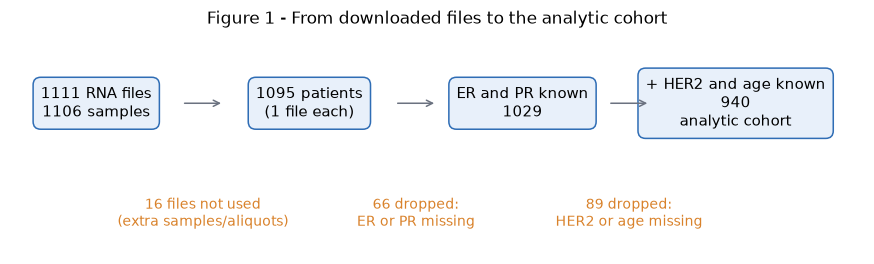

In [30]:
fig, ax = plt.subplots(figsize=(10, 2.6)); ax.axis("off")
boxes = [(0.00, f"{N_FILES} RNA files\n{N_SAMPLES} samples"), (0.25, f"{len(df)} patients\n(1 file each)"),
         (0.50, f"ER and PR known\n{int(flow.loc[2, 'patients'])}"), (0.75, f"+ HER2 and age known\n{int(flow.loc[4, 'patients'])}\nanalytic cohort")]
for x, txt in boxes:
    ax.text(x + 0.10, 0.68, txt, ha="center", va="center", fontsize=10, bbox=dict(boxstyle="round,pad=0.5", fc="#E8F0FA", ec=POS))
for x in (0.20, 0.45, 0.70):
    ax.annotate("", xy=(x + 0.05, 0.68), xytext=(x, 0.68), arrowprops=dict(arrowstyle="->", color=GREY))
notes = [(0.225, f"{N_FILES - len(df)} files not used\n(extra samples/aliquots)"), (0.475, f"{int(flow.loc[1, 'dropped'] + flow.loc[2, 'dropped'])} dropped:\nER or PR missing"),
         (0.725, f"{int(flow.loc[3, 'dropped'] + flow.loc[4, 'dropped'])} dropped:\nHER2 or age missing")]
for x, txt in notes:
    ax.text(x + 0.0, 0.18, txt, ha="center", va="center", fontsize=9, color=NEG)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_title("Figure 1 - From downloaded files to the analytic cohort")
save_fig(fig, "04_fig1_data_flow"); plt.show()
flow.to_csv(PROC / "flow_cohort.csv", index=False)

## 3. Included and excluded patients

Patients without complete receptor status and age may differ from those in the cohort; the two groups are compared descriptively.

In [31]:
df["group"] = np.where(df["in_cohort"], "Included", "Excluded")
num = ["age", PROLIF, "MKI67", "luminal_score", "ERBB2", "tumor_nuclei_pct"]
t = df.groupby("group")[num].agg(["count", "median"]).round(2)
display(t)
cat = pd.DataFrame({
    "Dead (%)": df.groupby("group")["vital_status"].apply(lambda s: round(100 * (s == "Dead").sum() / s.notna().sum(), 1)),
    "With tumour at last contact (%)": df.groupby("group")["last_contact_response"].apply(lambda s: round(100 * (s == "WT-With Tumor").sum() / s.notna().sum(), 1)),
    "Stage III-IV (%)": df.groupby("group")["stage"].apply(lambda s: round(100 * s.isin(["III", "IV"]).sum() / s.notna().sum(), 1)),
    "n": df.groupby("group").size()})
display(cat)

age        prolif_score        MKI67        luminal_score        ERBB2        tumor_nuclei_pct       
         count median        count median count median         count median count median            count median
group                                                                                                           
Excluded   154   58.0          155   4.74   155   4.56           155   0.37   155   6.94              155   80.0
Included   940   59.0          940   4.64   940   4.55           940   0.29   940   6.96              940   80.0

,Dead (%),With tumour at last contact (%),Stage III-IV (%),n
group,,,,
Excluded,33.1,26.6,32.2,155
Included,10.7,9.2,24.1,940


saved figures\04_fig2_included_vs_excluded.png


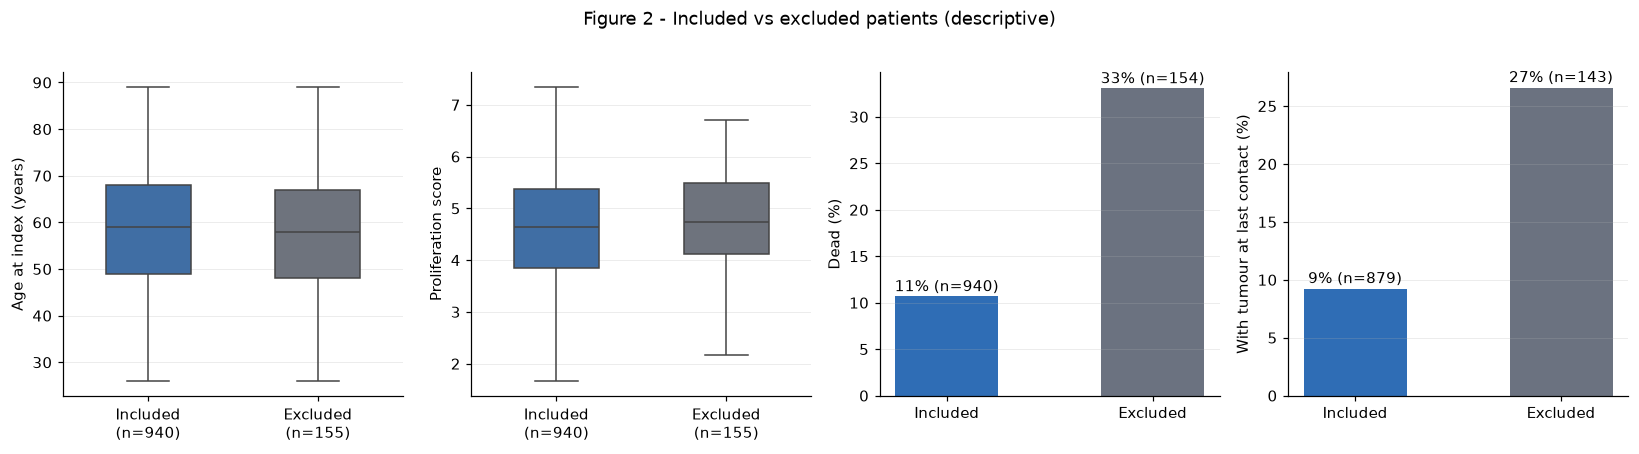

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
cols = {"Included": POS, "Excluded": GREY}
for ax, (v, lab) in zip(axes[:2], [("age", "Age at index (years)"), (PROLIF, "Proliferation score")]):
    sns.boxplot(data=df, x="group", y=v, order=["Included", "Excluded"], hue="group", hue_order=["Included", "Excluded"], palette=cols, legend=False, showfliers=False, width=0.5, ax=ax)
    ax.set_xlabel(""); ax.set_ylabel(lab)
    ax.set_xticks([0, 1]); ax.set_xticklabels([f"{g}\n(n={int((df['group']==g).sum())})" for g in ["Included", "Excluded"]])
for ax, (col, val, lab) in zip(axes[2:], [("vital_status", "Dead", "Dead (%)"), ("last_contact_response", "WT-With Tumor", "With tumour at last contact (%)")]):
    n_valid = [int(df.loc[df["group"] == g, col].notna().sum()) for g in ["Included", "Excluded"]]
    pct = [100 * (df.loc[df["group"] == g, col] == val).sum() / df.loc[df["group"] == g, col].notna().sum() for g in ["Included", "Excluded"]]
    ax.bar(["Included", "Excluded"], pct, color=[POS, GREY], width=0.5); ax.set_ylabel(lab)
    for i, p in enumerate(pct): ax.text(i, p + 0.5, f"{p:.0f}% (n={n_valid[i]})", ha="center")
    ax.grid(axis="x", visible=False)
fig.suptitle("Figure 2 - Included vs excluded patients (descriptive)", y=1.02)
fig.tight_layout(); save_fig(fig, "04_fig2_included_vs_excluded"); plt.show()

## 4. Descriptive tables for the analytic cohort

In [33]:
co = df[df["in_cohort"]].copy()
print(f"Analytic cohort: n = {len(co)}\n")
for c in ["ER", "PR", "HER2", "HER2_source", "subtype_surrogate", "stage", "sex", "vital_status"]:
    vc = co[c].value_counts(dropna=False)
    print(pd.DataFrame({"n": vc, "%": (100 * vc / len(co)).round(1)}).rename_axis(c).to_string(), "\n")
print("Receptor combinations (ER / PR / HER2):")
display(co.groupby(["ER", "PR", "HER2"]).size().rename("patients").reset_index().sort_values("patients", ascending=False))
num = ["age", PROLIF, "MKI67", "luminal_score", "ERBB2", "tumor_nuclei_pct", "lymph_nodes_positive"]
display(co[num].describe(percentiles=[.25, .5, .75]).T.round(2))

molecular_vars = [PROLIF, "MKI67", "luminal_score", "ERBB2"]

outlier_rows = []

for variable in molecular_vars:
    x = pd.to_numeric(co[variable], errors="coerce")
    valid = x.dropna()

    q1, q3 = valid.quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flagged = (valid < lower) | (valid > upper)

    outlier_rows.append({
        "variable": variable,
        "n": len(valid),
        "missing": x.isna().sum(),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower fence": lower,
        "upper fence": upper,
        "outliers": int(flagged.sum())
    })

display(
    pd.DataFrame(outlier_rows)
      .set_index("variable")
      .round(2)
)

Analytic cohort: n = 940

            n     %
ER                 
Positive  728  77.4
Negative  212  22.6 

            n     %
PR                 
Positive  632  67.2
Negative  308  32.8 

            n     %
HER2               
Negative  758  80.6
Positive  182  19.4 

               n     %
HER2_source           
IHC          533  56.7
FISH         407  43.3 

                     n     %
subtype_surrogate           
HR+/HER2-          599  63.7
HER2-positive      182  19.4
Triple-negative    159  16.9 

         n     %
stage           
II     541  57.6
III    209  22.2
I      162  17.2
NaN     14   1.5
IV      14   1.5 

          n     %
sex              
female  929  98.8
male     11   1.2 

                n     %
vital_status           
Alive         839  89.3
Dead          101  10.7 

Receptor combinations (ER / PR / HER2):


,ER,PR,HER2,patients
6,Positive,Positive,Negative,508
0,Negative,Negative,Negative,159
7,Positive,Positive,Positive,109
4,Positive,Negative,Negative,80
1,Negative,Negative,Positive,38
5,Positive,Negative,Positive,31
2,Negative,Positive,Negative,11
3,Negative,Positive,Positive,4


,count,mean,std,min,25%,50%,75%,max
age,940.0,58.67,13.12,26.00,49.00,59.00,68.00,89.00
prolif_score,940.0,4.59,1.08,1.39,3.84,4.64,5.37,7.34
MKI67,940.0,4.53,1.26,0.60,3.68,4.55,5.43,7.58
luminal_score,940.0,-0.01,0.88,-2.39,-0.40,0.29,0.63,1.34
ERBB2,940.0,7.07,1.54,1.73,6.21,6.96,7.61,12.53
tumor_nuclei_pct,940.0,77.05,11.00,15.00,70.00,80.00,85.00,98.00
lymph_nodes_positive,800.0,2.19,4.42,0.00,0.00,0.00,2.00,29.00


,n,missing,Q1,Q3,IQR,lower fence,upper fence,outliers
variable,,,,,,,,
prolif_score,940,0,3.84,5.37,1.53,1.55,7.67,1
MKI67,940,0,3.68,5.43,1.74,1.07,8.04,5
luminal_score,940,0,-0.40,0.63,1.03,-1.95,2.18,25
ERBB2,940,0,6.21,7.61,1.40,4.10,9.72,86


Potential outliers in the four molecular measures are identified using the 1.5 × IQR rule. They are retained unless a separate data-quality check indicates an error.

## 5. Proliferation, receptors and molecular variables

For each group: n, median [IQR], difference in medians, Cohen's d, and the probability of superiority P(Negative > Positive) computed from ranks (0.5 = no difference).

*MKI67* is one of the 17 genes used to calculate the primary proliferation score. Therefore, its secondary analysis is not an independent validation of that score; it is reported as a complementary single-gene analysis.

saved figures\04_fig3_response_distribution.png


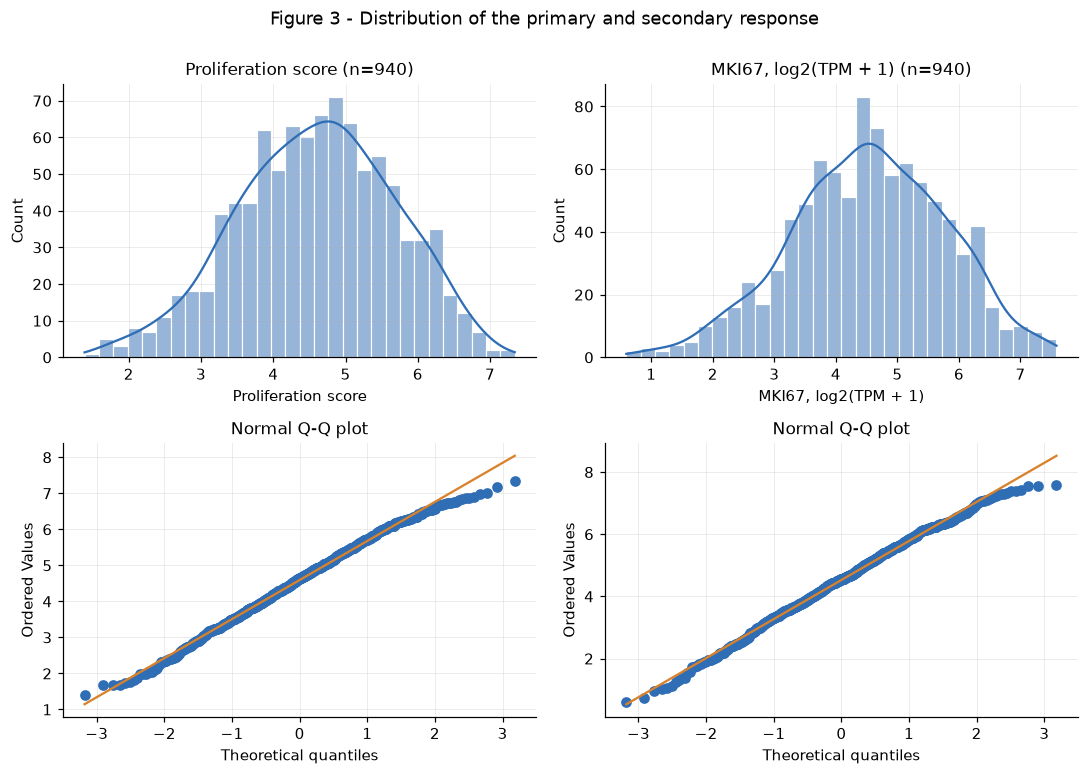

Skewness: score -0.18 | MKI67 -0.18


In [34]:
def effect(d, y, g, a, b):
    x, w = d.loc[d[g] == a, y].dropna(), d.loc[d[g] == b, y].dropna()
    sp = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(w) - 1) * w.var(ddof=1)) / (len(x) + len(w) - 2))
    pooled_ranks = stats.rankdata(np.concatenate([x.to_numpy(), w.to_numpy()]),method="average",)
    u = (pooled_ranks[:len(x)].sum() - len(x) * (len(x)+1)/2) 
    return {"contrast": f"{a} vs {b}", "n_a": len(x), "n_b": len(w), "median_a": x.median(), "median_b": w.median(),
            "median_diff": x.median() - w.median(), "cohens_d": (x.mean() - w.mean()) / sp, "prob_superiority": u / (len(x) * len(w))}

def violin(ax, d, x, y, order, colors, ylabel):
    sns.violinplot(data=d, x=x, y=y, order=order, hue=x, hue_order=order, palette=colors, inner=None, cut=0, linewidth=0.8, saturation=1, ax=ax, legend=False)
    for c in ax.collections: c.set_alpha(0.3)
    sns.stripplot(data=d, x=x, y=y, order=order, color=GREY, size=2.2, alpha=0.35, jitter=0.18, ax=ax)
    sns.boxplot(data=d, x=x, y=y, order=order, width=0.16, showfliers=False, ax=ax, boxprops=dict(facecolor="white", edgecolor="black", linewidth=0.9, zorder=3),
                medianprops=dict(color="black", linewidth=1.4))
    n = d.groupby(x)[y].count()
    ax.set_xticks(range(len(order))); ax.set_xticklabels([f"{g}\n(n={n.get(g, 0)})" for g in order])
    ax.set_xlabel(""); ax.set_ylabel(ylabel)

YL = "Proliferation score\n(mean log2 TPM+1, 17 genes)"

# Figure 3: distribution of the responses
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for j, (v, lab) in enumerate([(PROLIF, "Proliferation score"), ("MKI67", "MKI67, log2(TPM + 1)")]):
    sns.histplot(co[v], bins=30, kde=True, color=POS, edgecolor="white", ax=axes[0, j]); axes[0, j].set_xlabel(lab); axes[0, j].set_title(f"{lab} (n={len(co)})")
    stats.probplot(co[v], dist="norm", plot=axes[1, j]); axes[1, j].set_title("Normal Q-Q plot")
    axes[1, j].get_lines()[0].set_markerfacecolor(POS); axes[1, j].get_lines()[0].set_markeredgecolor(POS); axes[1, j].get_lines()[1].set_color(NEG)
fig.suptitle("Figure 3 - Distribution of the primary and secondary response", y=1.0)
fig.tight_layout(); save_fig(fig, "04_fig3_response_distribution"); plt.show()
print("Skewness: score", round(stats.skew(co[PROLIF]), 2), "| MKI67", round(stats.skew(co["MKI67"]), 2))

saved figures\04_fig4_prolif_by_receptor.png


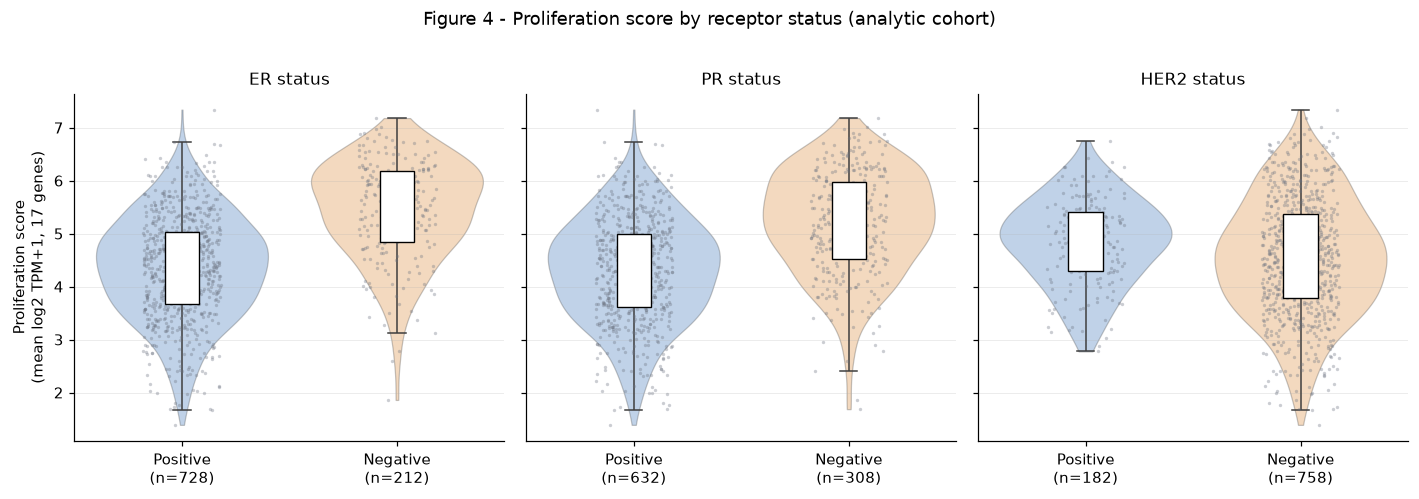

,contrast,n_a,n_b,median_a,median_b,median_diff,cohens_d,prob_superiority
receptor,,,,,,,,
ER,Negative vs Positive,212,728,5.572,4.383,1.189,1.098,0.789
PR,Negative vs Positive,308,632,5.283,4.329,0.953,0.905,0.741
HER2,Negative vs Positive,758,182,4.537,4.877,-0.340,-0.276,0.417


In [35]:
# Figure 4: proliferation score by ER, PR, HER2 (cohort)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
rows = []
for ax, r in zip(axes, ["ER", "PR", "HER2"]):
    violin(ax, co, r, PROLIF, ["Positive", "Negative"], STATUS, YL if r == "ER" else "")
    ax.set_title(f"{r} status")
    rows.append(effect(co, PROLIF, r, "Negative", "Positive") | {"receptor": r})
fig.suptitle("Figure 4 - Proliferation score by receptor status (analytic cohort)", y=1.02)
fig.tight_layout(); save_fig(fig, "04_fig4_prolif_by_receptor"); plt.show()
display(pd.DataFrame(rows).set_index("receptor").round(3))

saved figures\04_fig5_prolif_by_group.png


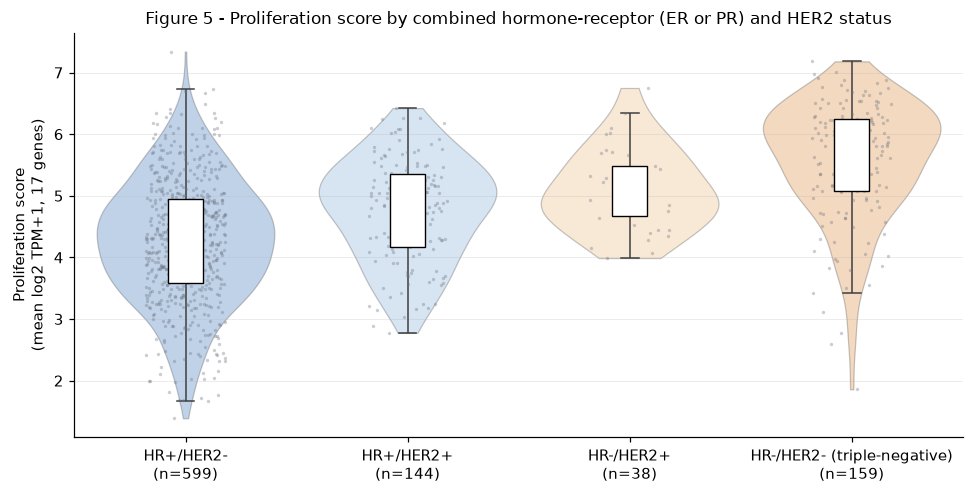

,n,median,Q1,Q3
hr_her2,,,,
HR+/HER2-,599,4.30,3.58,4.95
HR+/HER2+,144,4.85,4.18,5.35
HR-/HER2+,38,4.94,4.67,5.48
HR-/HER2- (triple-negative),159,5.80,5.08,6.24


Groups with fewer than 30 patients: none


In [36]:
# Figure 5: combined receptor groups
co["hr_her2"] = np.select([(co["HR"] == "Positive") & (co["HER2"] == "Negative"), (co["HR"] == "Positive") & (co["HER2"] == "Positive"),
                           (co["HR"] == "Negative") & (co["HER2"] == "Positive"), (co["HR"] == "Negative") & (co["HER2"] == "Negative")],
                          ["HR+/HER2-", "HR+/HER2+", "HR-/HER2+", "HR-/HER2- (triple-negative)"], default="")
order4 = ["HR+/HER2-", "HR+/HER2+", "HR-/HER2+", "HR-/HER2- (triple-negative)"]
col4 = {order4[0]: POS, order4[1]: "#7DA6D6", order4[2]: "#EAB57A", order4[3]: NEG}
fig, ax = plt.subplots(figsize=(9, 4.6))
violin(ax, co[co["hr_her2"] != ""], "hr_her2", PROLIF, order4, col4, YL)
ax.set_title("Figure 5 - Proliferation score by combined hormone-receptor (ER or PR) and HER2 status")
fig.tight_layout(); save_fig(fig, "04_fig5_prolif_by_group"); plt.show()
g = co[co["hr_her2"] != ""].groupby("hr_her2")[PROLIF].agg(n="count", median="median", Q1=lambda s: s.quantile(.25), Q3=lambda s: s.quantile(.75)).reindex(order4).round(2)
display(g)
print("Groups with fewer than 30 patients:", g.index[g["n"] < 30].tolist() or "none")

saved figures\04_fig6_molecular_relations.png


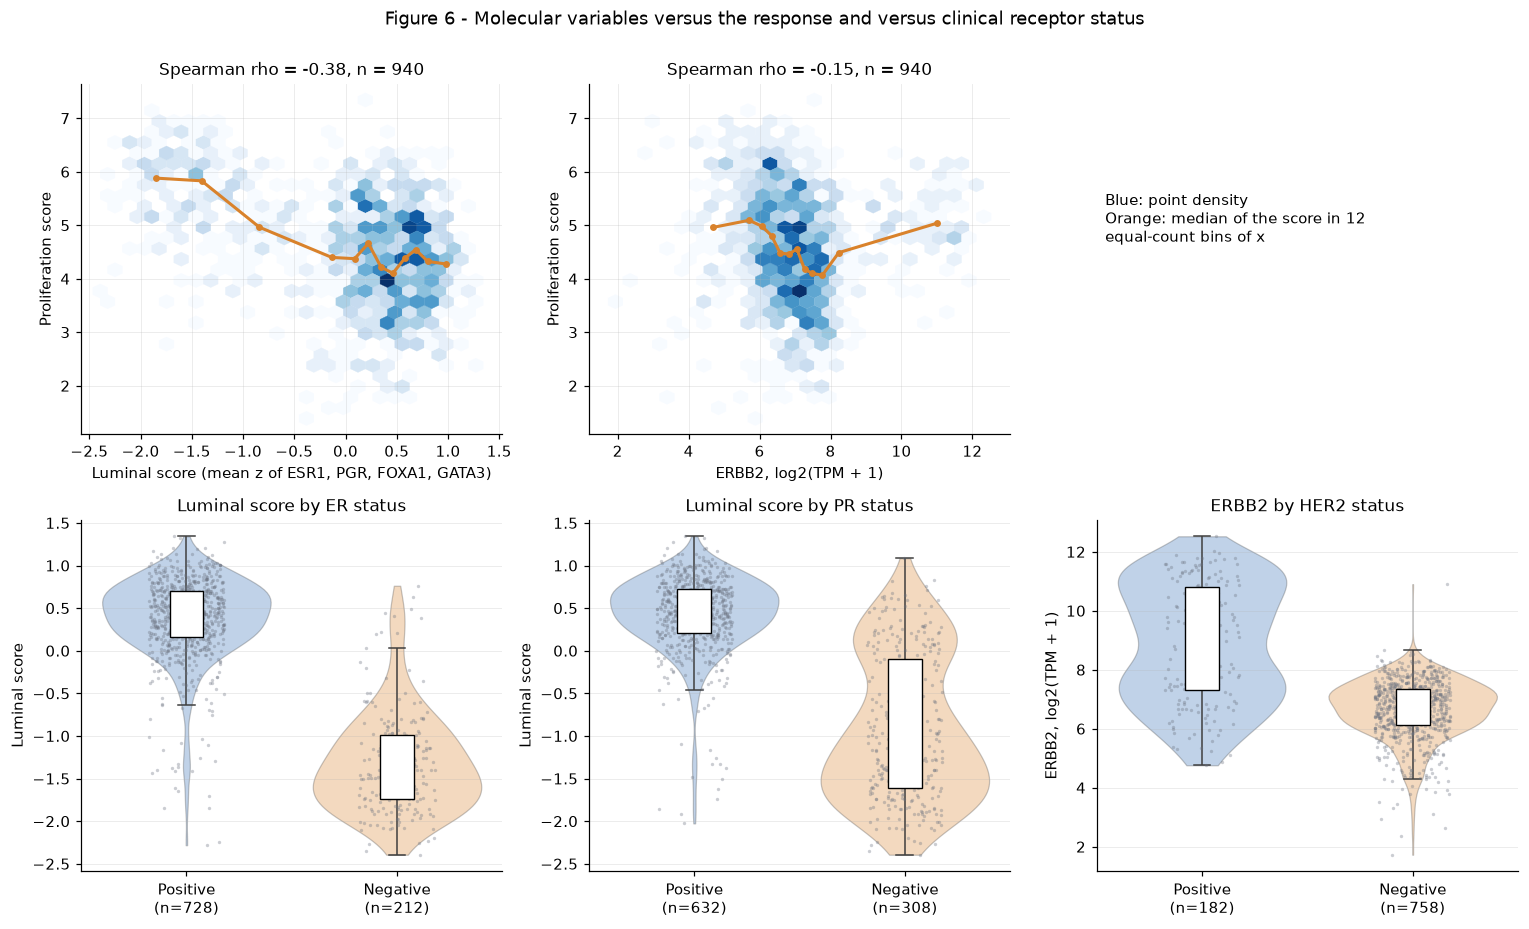

prob_superiority = P(value of a Positive patient > value of a Negative patient); 1 = perfect separation, 0.5 = none


,contrast,n_a,n_b,median_a,median_b,median_diff,cohens_d,prob_superiority,molecular
clinical,,,,,,,,,
ER,Positive vs Negative,728,212,0.437,-1.451,1.888,3.265,0.963,luminal_score
PR,Positive vs Negative,632,308,0.486,-1.112,1.599,2.195,0.904,luminal_score
HER2,Positive vs Negative,182,758,9.000,6.782,2.218,1.749,0.812,ERBB2


In [37]:
# Figure 6: relation between the molecular variables and the clinical receptors
def binned(x, y, q=12):
    d = pd.DataFrame({"x": x, "y": y}).dropna(); d["b"] = pd.qcut(d["x"], q, duplicates="drop")
    return d.groupby("b", observed=True).agg(x=("x", "median"), y=("y", "median"))

fig, axes = plt.subplots(2, 3, figsize=(14, 8.4))
for ax, (xv, xl) in zip(axes[0, :2], [("luminal_score", "Luminal score (mean z of ESR1, PGR, FOXA1, GATA3)"), ("ERBB2", "ERBB2, log2(TPM + 1)")]):
    ax.hexbin(co[xv], co[PROLIF], gridsize=26, mincnt=1, cmap="Blues", linewidths=0.2)
    b = binned(co[xv], co[PROLIF]); ax.plot(b["x"], b["y"], color=NEG, lw=2, marker="o", ms=3.5)
    ax.set_xlabel(xl); ax.set_ylabel("Proliferation score")
    ax.set_title(f"Spearman rho = {stats.spearmanr(co[xv], co[PROLIF])[0]:.2f}, n = {len(co)}")
axes[0, 2].axis("off")
axes[0, 2].text(0.02, 0.55, "Blue: point density\nOrange: median of the score in 12\nequal-count bins of x", fontsize=10)
pairs = [("ER", "luminal_score", "Luminal score"), ("PR", "luminal_score", "Luminal score"), ("HER2", "ERBB2", "ERBB2, log2(TPM + 1)")]
conc = []
for ax, (r, v, lab) in zip(axes[1], pairs):
    violin(ax, co, r, v, ["Positive", "Negative"], STATUS, lab); ax.set_title(f"{lab.split(',')[0]} by {r} status")
    conc.append(effect(co, v, r, "Positive", "Negative") | {"clinical": r, "molecular": v})
fig.suptitle("Figure 6 - Molecular variables versus the response and versus clinical receptor status", y=1.0)
fig.tight_layout(); save_fig(fig, "04_fig6_molecular_relations"); plt.show()
print("prob_superiority = P(value of a Positive patient > value of a Negative patient); 1 = perfect separation, 0.5 = none")
display(pd.DataFrame(conc).set_index("clinical").round(3))

### Age, stage and tumour nuclei

Age, stage and tumour-nuclei percentage may relate to both receptor status and the proliferation score. Bulk RNA mixes tumour and non-tumour cells, so a low tumour fraction lowers tumour-derived transcripts.

saved figures\04_fig7_confounders.png


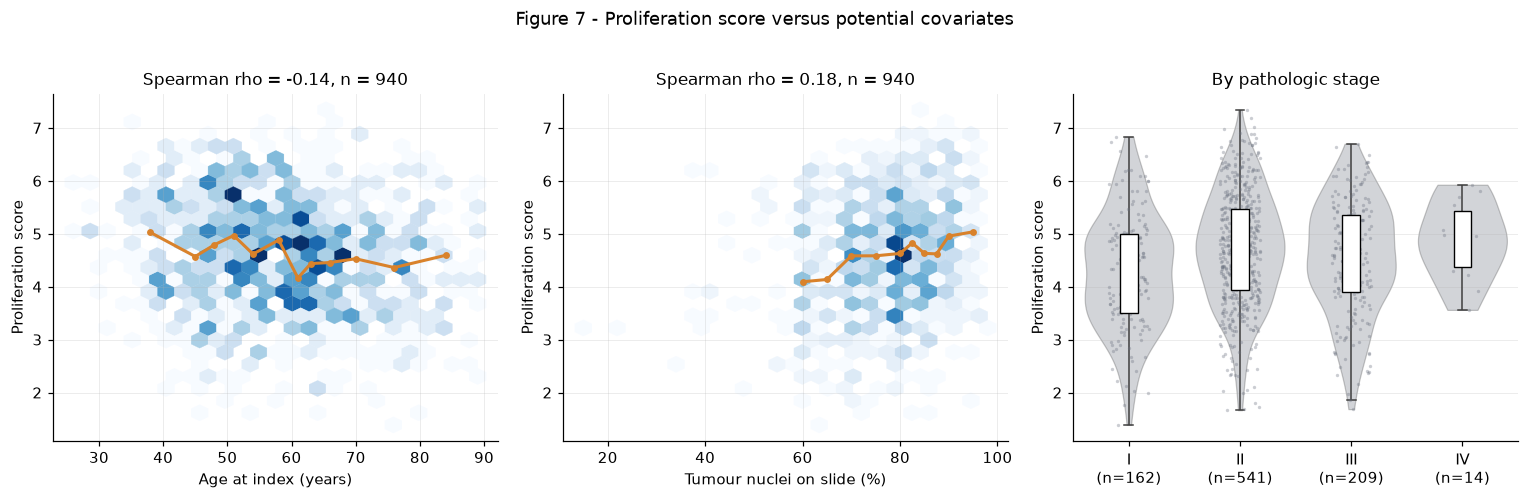

age        tumor_nuclei_pct       
         count median            count median
ER                                           
Negative   212   55.0              212   80.0
Positive   728   59.5              728   80.0

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (v, lab) in zip(axes[:2], [("age", "Age at index (years)"), ("tumor_nuclei_pct", "Tumour nuclei on slide (%)")]):
    d = co[[v, PROLIF]].dropna()
    ax.hexbin(d[v], d[PROLIF], gridsize=24, mincnt=1, cmap="Blues", linewidths=0.2)
    b = binned(d[v], d[PROLIF]); ax.plot(b["x"], b["y"], color=NEG, lw=2, marker="o", ms=3.5)
    ax.set_xlabel(lab); ax.set_ylabel("Proliferation score"); ax.set_title(f"Spearman rho = {stats.spearmanr(d[v], d[PROLIF])[0]:.2f}, n = {len(d)}")
stg = ["I", "II", "III", "IV"]
violin(axes[2], co[co["stage"].isin(stg)], "stage", PROLIF, stg, {s: GREY for s in stg}, "Proliferation score"); axes[2].set_title("By pathologic stage")
fig.suptitle("Figure 7 - Proliferation score versus potential covariates", y=1.02)
fig.tight_layout(); save_fig(fig, "04_fig7_confounders"); plt.show()
display(co.groupby("ER")[["age", "tumor_nuclei_pct"]].agg(["count", "median"]).round(1))

## 6. Final question

**Title.** *Tumour Proliferation and Receptor Status in TCGA-BRCA: Does RNA Expression Add to Clinical Information?*

**Question.** Among TCGA-BRCA breast cancer patients, does adding RNA-derived molecular information (a luminal-program score and *ERBB2* expression) to clinical information (ER, PR and HER2 status and age) explain additional variation in tumour proliferation, measured as a 17-gene expression score?

**Variables.** Response: proliferation score. Clinical: ER, PR, HER2, age. Molecular: luminal score, *ERBB2*.

The multi-gene score was preferred to *MKI67* alone after exploratory plots, because one gene is a noisier measure of proliferation; *MKI67* is kept as a secondary measure.

In [39]:
cols = ["patient_submitter_id", "sample_submitter_id", "file_id", "in_cohort", "age", "sex", "race", "vital_status", "stage", "t_stage", "n_stage",
        "histology", "year_of_diagnosis", "ER", "PR", "HER2", "HER2_source", "HR", "ER_HER2", "subtype_surrogate", "ER_pos", "PR_pos", "HER2_pos",
        "last_contact_days", "last_contact_response", "max_followup_days", "days_to_death", "lymph_nodes_positive", "lymph_nodes_tested",
        "tumor_nuclei_pct", "prolif_score", "MKI67", "luminal_score", "ERBB2"]
extra = [c for c in df.columns if c.endswith("_TPM") or c in ["ESR1", "PGR", "FOXA1", "GATA3", "GRB7", "EGFR", "FOXC1", "TFF1"]]
df[cols + extra].to_csv(PROC / "analysis_table.csv", index=False)
print("Saved analysis_table.csv:", df[cols + extra].shape, "| analytic cohort:", int(df["in_cohort"].sum()))

Saved analysis_table.csv: (1095, 42) | analytic cohort: 940
